# Project 03 — Community Waste Collection and Sorting Assistant
## Complete Google Colab model-training notebook

**Important:** This notebook uses only `Project_03` from the supplied ZIP. It preserves the supplied train/validation/test splits and the assignment's required models and workflow.

### What this notebook does
1. Loads and validates the supplied Project 03 data.
2. Trains and evaluates the Decision Tree and a DummyClassifier baseline.
3. Fits KMeans with exactly 3 clusters.
4. Trains the small CNN for a maximum of 3 epochs using the supplied fixed image splits.
5. Evaluates the supplied English comments with NLTK VADER and the supplied topic keywords.
6. Saves the trained models, metadata, metrics and charts in `Project_03/models` and `Project_03/reports`.

**Accuracy note:** No code can guarantee a particular accuracy or a tiny training-validation gap. We will avoid leakage, use validation for checks, and use the test split only for final evaluation. A small gap alone does not prove a good model.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Cell 1 — Upload the supplied ZIP

Run this cell and select `AI_for_Everyone_Ready_Datasets.zip` from your computer. Colab sessions are temporary, so download the final `Project_03` folder or save it to Google Drive before closing the session.

In [ ]:
from google.colab import files
uploaded = files.upload()  # Select AI_for_Everyone_Ready_Datasets.zip

zip_candidates = [name for name in uploaded if name.lower().endswith(".zip")]
assert zip_candidates, "ZIP file upload nahi hui. Supplied dataset ZIP select karein."
ARCHIVE_PATH = zip_candidates[0]
print("Uploaded:", ARCHIVE_PATH)

Saving AI_for_Everyone_Ready_Datasets.zip to AI_for_Everyone_Ready_Datasets.zip
Uploaded: AI_for_Everyone_Ready_Datasets.zip


## Cell 2 — Read & Extract the ZIP File from Drive and select Project_03 only

The ZIP contains multiple projects. We explicitly point to `Project_03` so files from Project 01 or Project 02 are not accidentally used.

In [6]:

# Permanent Project Setup on Google Drive

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import zipfile

# Permanent Google Drive project folder
DRIVE_ROOT = Path(
    "/content/drive/MyDrive/Community_Waste_Project"
)

DRIVE_ROOT.mkdir(parents=True, exist_ok=True)

# ZIP location
ARCHIVE_PATH = Path(
    "/content/drive/MyDrive/AI_for_Everyone_Ready_Datasets.zip"
)

assert ARCHIVE_PATH.exists(), (
    "Dataset ZIP Google Drive MyDrive mein nahi mili."
)

# Extract only once
EXTRACT_ROOT = DRIVE_ROOT / "source"

PROJECT_DIR = (
    EXTRACT_ROOT /
    "AI_for_Everyone_Ready_Datasets" /
    "Project_03"
)

if not PROJECT_DIR.exists():

    EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(ARCHIVE_PATH, "r") as archive:

        bad_member = archive.testzip()

        if bad_member is not None:
            raise RuntimeError(
                f"ZIP integrity problem: {bad_member}"
            )

        archive.extractall(EXTRACT_ROOT)

DATA = PROJECT_DIR / "data"
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

assert DATA.exists(), "Project_03 data folder missing."

print("Project:", PROJECT_DIR)
print("Models:", MODELS_DIR)
print("Reports:", REPORTS_DIR)
print("Permanent Drive setup completed.")


Mounted at /content/drive
Project: /content/drive/MyDrive/Community_Waste_Project/source/AI_for_Everyone_Ready_Datasets/Project_03
Models: /content/drive/MyDrive/Community_Waste_Project/source/AI_for_Everyone_Ready_Datasets/Project_03/models
Reports: /content/drive/MyDrive/Community_Waste_Project/source/AI_for_Everyone_Ready_Datasets/Project_03/reports
Permanent Drive setup completed.


## Cell 3 — Install only the extra package and import libraries

Colab already includes most scientific and TensorFlow packages. We install NLTK only if needed; do not reinstall or upgrade TensorFlow unnecessarily.

In [7]:
%pip -q install nltk

import json, os, sys, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
import joblib
import nltk

from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Cell 4 — Load CSV files, metadata and image arrays

`images.npz` is loaded with `allow_pickle=False` as specified. The supplied images are already 96×96 RGB arrays with values from 0 to 255.

In [8]:
meta = json.loads((DATA / "meta.json").read_text())
main = pd.read_csv(DATA / "main.csv")
feedback = pd.read_csv(DATA / "feedback.csv")
images = np.load(DATA / "images.npz", allow_pickle=False)
topic_keywords = json.loads((DATA / "topic_keywords.json").read_text())

print("Project:", meta["title"])
print("Main shape:", main.shape)
print("Feedback shape:", feedback.shape)
print("Image arrays:", {key: images[key].shape for key in images.files})
print("Main split counts:")
display(main["split"].value_counts().reindex(["train", "validation", "test"]))

Project: Community Waste Collection and Sorting Assistant
Main shape: (1000, 8)
Feedback shape: (30, 3)
Image arrays: {'x_train': (630, 96, 96, 3), 'y_train': (630,), 'x_validation': (135, 96, 96, 3), 'y_validation': (135,), 'x_test': (135, 96, 96, 3), 'y_test': (135,)}
Main split counts:


,count
split,
train,700
validation,150
test,150


## Cell 5 — Data integrity checks (do not skip)

These checks verify the expected columns, split sizes, allowed categories, feature ranges, image shapes, class order and missing values before training.

In [9]:
required_main = ["record_id"] + meta["numeric_features"] + meta["categorical_features"] + [meta["target"], "split"]
assert set(required_main).issubset(main.columns), "main.csv required columns missing."
assert len(main) == meta["tabular_rows"], "Unexpected number of main.csv rows."
assert main["record_id"].is_unique, "record_id values must be unique."
assert main["split"].value_counts().to_dict() == meta["tabular_split_counts"], "Main split sizes do not match meta.json."
assert not main[required_main].isna().any().any(), "Missing values found in required main.csv columns."

for feature, bounds in meta["numeric_ranges"].items():
    low, high = bounds
    assert main[feature].between(low, high).all(), f"{feature} has values outside {bounds}."

allowed_locations = meta["category_values"]["location_type"]
assert set(main["location_type"].unique()).issubset(set(allowed_locations)), "Unexpected location_type value."
assert set(main[meta["target"]].unique()).issubset({0, 1}), "Target must be binary."

expected_img = meta["image_shape"]
for split_name, expected_count in meta["image_split_counts"].items():
    x = images["x_" + split_name]
    y = images["y_" + split_name]
    assert x.shape == (expected_count, *expected_img), f"Unexpected x_{split_name} shape: {x.shape}"
    assert y.shape == (expected_count,), f"Unexpected y_{split_name} shape: {y.shape}"
    assert x.dtype == np.uint8 and x.min() >= 0 and x.max() <= 255
    assert set(np.unique(y)).issubset(set(range(len(meta["image_classes"]))))

assert len(feedback) == meta["feedback_rows"]
assert {"text", "sentiment_label"}.issubset(feedback.columns)

print("All dataset integrity checks passed.")
print("Numeric features:", meta["numeric_features"])
print("Categorical features:", meta["categorical_features"])
print("Target:", meta["target"], "-", meta["target_definition"])
print("Image class order:", meta["image_classes"])

All dataset integrity checks passed.
Numeric features: ['fill_pct', 'days_since_collection', 'footfall', 'capacity_l']
Categorical features: ['location_type']
Target: needs_collection - Set needs_collection to 1 when the simulated next morning fill level reaches 90 percent, otherwise 0. The future fill value creates the teaching label and must not be a predictor. The 90 percent threshold is an exercise setting.
Image class order: ['paper', 'plastic', 'metal']


## Cell 6 — Explore the tabular data and make the required three charts

Only the training split is used for these descriptive training-data charts. The supplied values are generated classroom scenarios, not real operational sensor readings.

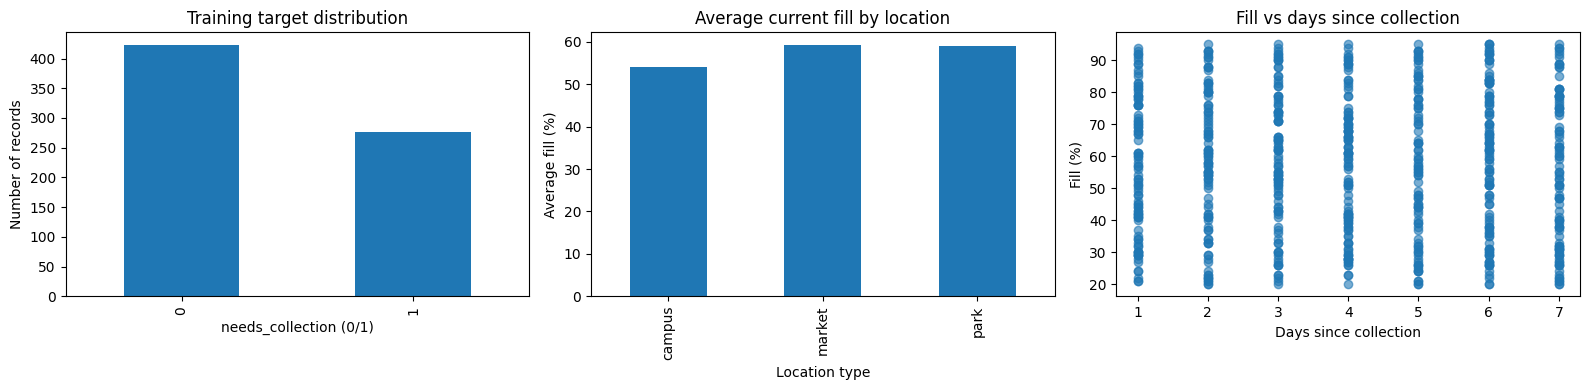

,record_id,fill_pct,days_since_collection,footfall,capacity_l,location_type,needs_collection,split
0,P03_0001,26,6,266,120,park,0,train
2,P03_0003,69,4,131,120,park,1,train
3,P03_0004,53,7,148,120,campus,1,train
5,P03_0006,85,7,56,80,market,1,train
6,P03_0007,26,6,141,80,park,0,train


In [10]:
train_df = main.loc[main["split"] == "train"].copy()
val_df = main.loc[main["split"] == "validation"].copy()
test_df = main.loc[main["split"] == "test"].copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

train_df[meta["target"]].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], title="Training target distribution"
)
axes[0].set_xlabel("needs_collection (0/1)")
axes[0].set_ylabel("Number of records")

train_df.groupby("location_type")["fill_pct"].mean().plot(
    kind="bar", ax=axes[1], title="Average current fill by location"
)
axes[1].set_xlabel("Location type")
axes[1].set_ylabel("Average fill (%)")

axes[2].scatter(train_df["days_since_collection"], train_df["fill_pct"], alpha=0.6)
axes[2].set_title("Fill vs days since collection")
axes[2].set_xlabel("Days since collection")
axes[2].set_ylabel("Fill (%)")

plt.tight_layout()
plt.savefig(REPORTS_DIR / "tabular_eda.png", dpi=160, bbox_inches="tight")
plt.show()

display(train_df.head())

# Part A — Supervised Learning: Decision Tree

## Cell 7 — Prepare fixed splits and build the required pipeline

**Important leakage prevention:** `record_id`, `split`, and the target are not predictors. The future-fill value is not present as a model input. We use only the exact features listed in `meta.json`.

The assignment's required starter configuration is a Decision Tree with `max_depth=4`. We keep that setting rather than running a large search that could overfit this small teaching dataset.

In [11]:
num_features = meta["numeric_features"]
cat_features = meta["categorical_features"]
features = num_features + cat_features
target = meta["target"]

X_train, y_train = train_df[features], train_df[target]
X_val, y_val = val_df[features], val_df[target]
X_test, y_test = test_df[features], test_df[target]

# Compatible with both newer and older scikit-learn versions.
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = make_column_transformer(
    (encoder, cat_features),
    remainder="passthrough"
)

decision_tree = make_pipeline(
    preprocessor,
    DecisionTreeClassifier(max_depth=4, random_state=SEED)
)

decision_tree.fit(X_train, y_train)
print("Decision Tree training completed.")

Decision Tree training completed.


## Cell 8 — Compare with the simple baseline on validation data

The DummyClassifier is a required reference baseline. The validation set is used to check the model before the final test evaluation.

In [12]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

val_pred_tree = decision_tree.predict(X_val)
val_pred_base = baseline.predict(X_val)

def binary_metrics(y_true, y_pred):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "class_1_precision": float(precision_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "class_1_recall": float(recall_score(y_true, y_pred, pos_label=1, zero_division=0))
    }

validation_comparison = pd.DataFrame([
    {"model": "Dummy baseline", **binary_metrics(y_val, val_pred_base)},
    {"model": "Decision Tree (depth=4)", **binary_metrics(y_val, val_pred_tree)}
])
display(validation_comparison.round(4))

,model,accuracy,macro_f1,class_1_precision,class_1_recall
0,Dummy baseline,0.6067,0.3776,0.0000,0.0000
1,Decision Tree (depth=4),0.8533,0.8512,0.7534,0.9322


## Cell 9 — Final test evaluation (run once after model choice)

Do not tune the model using test results. This is the held-out final evaluation. Keep the report honest even if the baseline performs similarly or better.

,model,accuracy,macro_f1,class_1_precision,class_1_recall
0,Dummy baseline,0.6067,0.3776,0.0000,0.0000
1,Decision Tree (depth=4),0.8800,0.8763,0.8154,0.8983


Decision Tree classification report:
               precision    recall  f1-score   support

No review (0)       0.93      0.87      0.90        91
   Review (1)       0.82      0.90      0.85        59

     accuracy                           0.88       150
    macro avg       0.87      0.88      0.88       150
 weighted avg       0.88      0.88      0.88       150



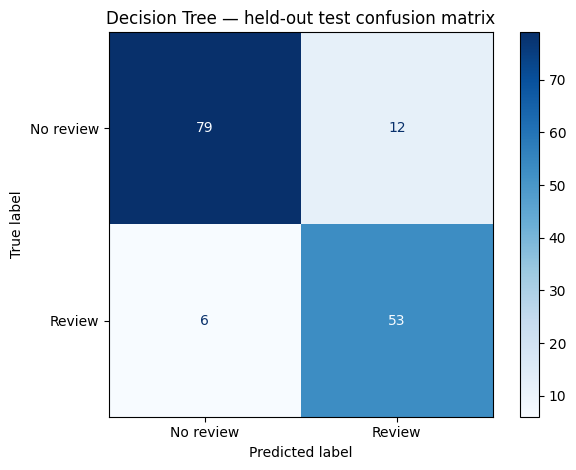

,record_id,fill_pct,days_since_collection,footfall,capacity_l,location_type,actual,predicted
23,P03_0105,80,3,264,120,park,0,1
25,P03_0108,70,7,58,80,market,0,1
26,P03_0130,68,5,110,120,campus,1,0
40,P03_0226,43,7,194,120,park,1,0
45,P03_0284,57,6,241,40,campus,0,1


In [13]:
test_pred_tree = decision_tree.predict(X_test)
test_pred_base = baseline.predict(X_test)

test_comparison = pd.DataFrame([
    {"model": "Dummy baseline", **binary_metrics(y_test, test_pred_base)},
    {"model": "Decision Tree (depth=4)", **binary_metrics(y_test, test_pred_tree)}
])
display(test_comparison.round(4))

print("Decision Tree classification report:")
print(classification_report(y_test, test_pred_tree, labels=[0, 1],
                            target_names=["No review (0)", "Review (1)"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred_tree, labels=[0, 1],
    display_labels=["No review", "Review"], cmap="Blues"
)
plt.title("Decision Tree — held-out test confusion matrix")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "decision_tree_test_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

# Save a small set of test errors for the written report.
test_result = test_df[["record_id"] + features].copy().reset_index(drop=True)
test_result["actual"] = y_test.to_numpy()
test_result["predicted"] = test_pred_tree
test_errors = test_result[test_result["actual"] != test_result["predicted"]].head(5)
display(test_errors)
test_errors.to_csv(REPORTS_DIR / "decision_tree_test_errors.csv", index=False)

## Cell 10 — Save the Decision Tree, baseline and metadata

The app will load these saved files. It must not train the model again when a user clicks a button.

In [14]:
joblib.dump(decision_tree, MODELS_DIR / "supervised.joblib")
joblib.dump(baseline, MODELS_DIR / "baseline.joblib")

supervised_metadata = {
    "features": features,
    "numeric_features": num_features,
    "categorical_features": cat_features,
    "target": target,
    "target_definition": meta["target_definition"],
    "decision_tree_max_depth": 4,
    "random_state": SEED,
    "class_labels": {"0": "No collection review", "1": "Collection review"}
}
(MODELS_DIR / "supervised_metadata.json").write_text(json.dumps(supervised_metadata, indent=2))

supervised_results = {
    "validation": validation_comparison.to_dict(orient="records"),
    "test": test_comparison.to_dict(orient="records")
}
(REPORTS_DIR / "supervised_metrics.json").write_text(json.dumps(supervised_results, indent=2))
print("Saved supervised.joblib and supporting metadata.")

Saved supervised.joblib and supporting metadata.


# Part B — Unsupervised Learning: KMeans

## Cell 11 — Fit exactly 3 clusters on training rows

KMeans does not use `needs_collection`. It groups similar observations using only the four supplied cluster features. Scaling is inside the saved pipeline, so new records will receive the same preprocessing.

In [15]:
cluster_features = meta["cluster_features"]
cluster_model = make_pipeline(
    StandardScaler(),
    KMeans(n_clusters=3, n_init=10, random_state=SEED)
)

train_cluster_ids = cluster_model.fit_predict(train_df[cluster_features])

cluster_profiles = train_df[cluster_features].copy()
cluster_profiles["group"] = train_cluster_ids

cluster_summary = cluster_profiles.groupby("group").agg(
    count=("fill_pct", "size"),
    fill_pct_mean=("fill_pct", "mean"),
    days_since_collection_mean=("days_since_collection", "mean"),
    footfall_mean=("footfall", "mean"),
    capacity_l_mean=("capacity_l", "mean")
).round(2)

display(cluster_summary)

,count,fill_pct_mean,days_since_collection_mean,footfall_mean,capacity_l_mean
group,,,,,
0,239,57.58,3.77,91.87,59.92
1,244,54.57,4.23,165.48,118.52
2,217,60.63,4.08,236.24,58.80


## Cell 12 — Visualize and name the groups from their actual averages

Cluster numbers are arbitrary. Do not describe group 0 as automatically better or worse than group 1. Use the measured averages to write the descriptions.

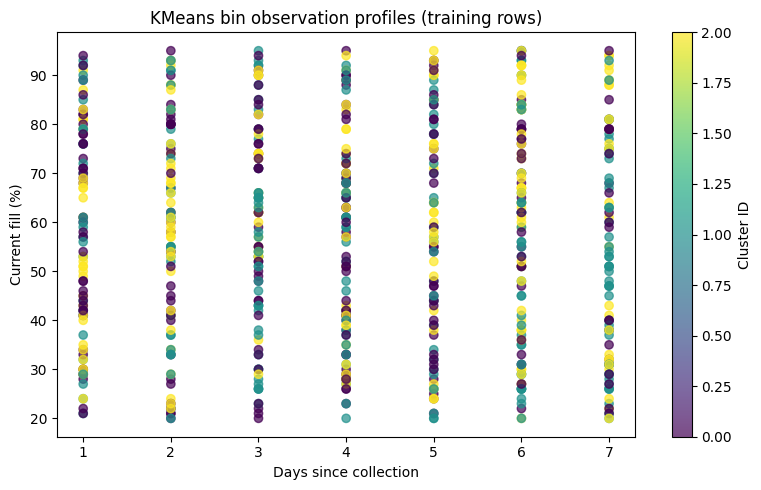

{
  "0": "Higher average fill with comparatively lower footfall",
  "1": "Lower average fill with higher footfall",
  "2": "Higher average fill and higher average footfall"
}


In [16]:
plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    cluster_profiles["days_since_collection"],
    cluster_profiles["fill_pct"],
    c=cluster_profiles["group"],
    alpha=0.7
)
plt.xlabel("Days since collection")
plt.ylabel("Current fill (%)")
plt.title("KMeans bin observation profiles (training rows)")
plt.colorbar(scatter, label="Cluster ID")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "kmeans_profiles.png", dpi=160, bbox_inches="tight")
plt.show()

# Draft descriptions based on group means; inspect and edit wording if needed.
group_descriptions = {}
for group_id, row in cluster_summary.iterrows():
    fill = row["fill_pct_mean"]
    footfall = row["footfall_mean"]
    if fill >= cluster_summary["fill_pct_mean"].median() and footfall >= cluster_summary["footfall_mean"].median():
        description = "Higher average fill and higher average footfall"
    elif fill >= cluster_summary["fill_pct_mean"].median():
        description = "Higher average fill with comparatively lower footfall"
    elif footfall >= cluster_summary["footfall_mean"].median():
        description = "Lower average fill with higher footfall"
    else:
        description = "Lower average fill and lower average footfall"
    group_descriptions[str(int(group_id))] = description

print(json.dumps(group_descriptions, indent=2))

## Cell 13 — Save KMeans and group descriptions

In [17]:
joblib.dump(cluster_model, MODELS_DIR / "clusters.joblib")
cluster_metadata = {
    "features": cluster_features,
    "n_clusters": 3,
    "random_state": SEED,
    "group_descriptions": group_descriptions,
    "training_group_summary": cluster_summary.reset_index().to_dict(orient="records")
}
(MODELS_DIR / "cluster_metadata.json").write_text(json.dumps(cluster_metadata, indent=2))
cluster_summary.to_csv(REPORTS_DIR / "kmeans_group_summary.csv")
print("Saved clusters.joblib and cluster metadata.")

Saved clusters.joblib and cluster metadata.


# Part C — CNN Image Classifier

## Cell 14 — Inspect supplied image arrays and class balance

The class order must remain exactly as given in `meta.json`: paper, plastic, metal. The image arrays are already RGB, 96×96 and uint8.

Class order: ['paper', 'plastic', 'metal']
train {'paper': 210, 'plastic': 210, 'metal': 210}
validation {'paper': 45, 'plastic': 45, 'metal': 45}
test {'paper': 45, 'plastic': 45, 'metal': 45}


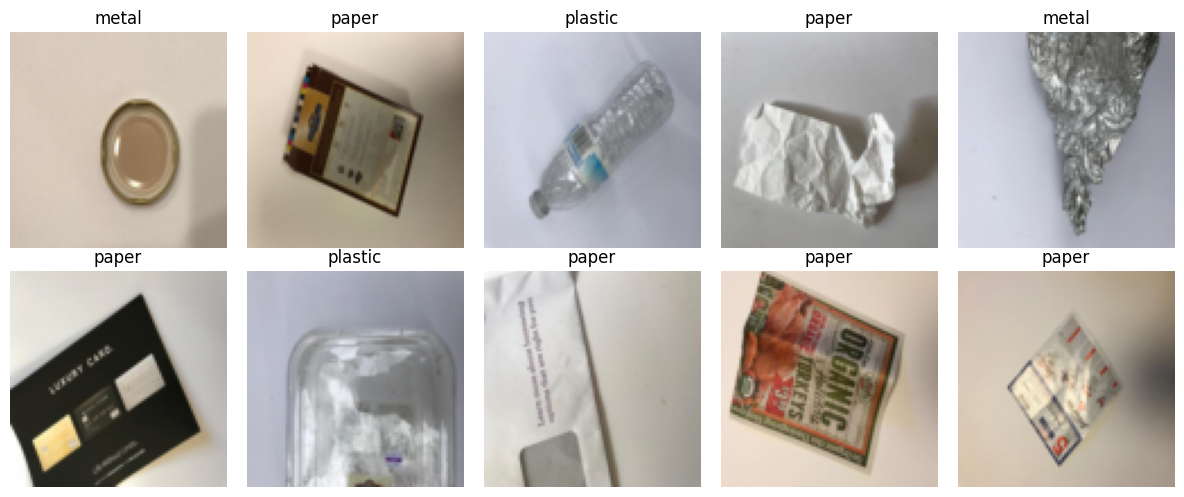

In [18]:
class_names = meta["image_classes"]
x_train_img, y_train_img = images["x_train"], images["y_train"]
x_val_img, y_val_img = images["x_validation"], images["y_validation"]
x_test_img, y_test_img = images["x_test"], images["y_test"]

print("Class order:", class_names)
for split_name, labels in [("train", y_train_img), ("validation", y_val_img), ("test", y_test_img)]:
    counts = np.bincount(labels, minlength=len(class_names))
    print(split_name, dict(zip(class_names, counts.tolist())))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_img[i])
    ax.set_title(class_names[int(y_train_img[i])])
    ax.axis("off")
plt.tight_layout()
plt.show()

# Cell 15 -- Dataset Split and Label Alignment Verification

In [19]:

import numpy as np

print("=" * 65)
print("DATASET SPLIT VERIFICATION")
print("=" * 65)

splits = [
    ("TRAIN", x_train_img, y_train_img),
    ("VALIDATION", x_val_img, y_val_img),
    ("TEST", x_test_img, y_test_img)
]

for name, x, y in splits:

    print(f"\n{name}")

    print("Images:", x.shape)
    print("Labels:", y.shape)

    print("Image dtype:", x.dtype)
    print("Label dtype:", y.dtype)

    print("Labels valid:",
          np.all((y >= 0) & (y < len(class_names))))

    print("Images contain NaN:",
          np.isnan(x).any())

    print("Images contain Inf:",
          np.isinf(x).any())

    print("Class distribution:")

    counts = np.bincount(
        y.astype(int),
        minlength=len(class_names)
    )

    for class_id, class_name in enumerate(class_names):
        print(class_name, ":", counts[class_id])

print("\n" + "=" * 65)
print("SPLIT SIZE CHECK")
print("=" * 65)

print("Total images:",
      len(x_train_img) + len(x_val_img) + len(x_test_img))

print("Total labels:",
      len(y_train_img) + len(y_val_img) + len(y_test_img))

print("\nVERIFICATION COMPLETED")


DATASET SPLIT VERIFICATION

TRAIN
Images: (630, 96, 96, 3)
Labels: (630,)
Image dtype: uint8
Label dtype: int64
Labels valid: True
Images contain NaN: False
Images contain Inf: False
Class distribution:
paper : 210
plastic : 210
metal : 210

VALIDATION
Images: (135, 96, 96, 3)
Labels: (135,)
Image dtype: uint8
Label dtype: int64
Labels valid: True
Images contain NaN: False
Images contain Inf: False
Class distribution:
paper : 45
plastic : 45
metal : 45

TEST
Images: (135, 96, 96, 3)
Labels: (135,)
Image dtype: uint8
Label dtype: int64
Labels valid: True
Images contain NaN: False
Images contain Inf: False
Class distribution:
paper : 45
plastic : 45
metal : 45

SPLIT SIZE CHECK
Total images: 900
Total labels: 900

VERIFICATION COMPLETED


# Cell 16 -- Inspect CNN Dataset Metadata

In [20]:

import json
import numpy as np

print("=" * 60)
print("DATASET METADATA")
print("=" * 60)

print(json.dumps(meta, indent=4))

print("\n" + "=" * 60)
print("NPZ FILE INFORMATION")
print("=" * 60)

for key in images.files:

    arr = images[key]

    print("\nArray:", key)
    print("Shape:", arr.shape)
    print("Data type:", arr.dtype)

    if arr.size > 0:
        print("Minimum:", np.min(arr))
        print("Maximum:", np.max(arr))

print("\nMETADATA INSPECTION COMPLETED")


DATASET METADATA
{
    "project_id": 3,
    "title": "Community Waste Collection and Sorting Assistant",
    "tabular_source": "Generated tabular practice data",
    "generated_data": true,
    "target": "needs_collection",
    "target_definition": "Set needs_collection to 1 when the simulated next morning fill level reaches 90 percent, otherwise 0. The future fill value creates the teaching label and must not be a predictor. The 90 percent threshold is an exercise setting.",
    "task": "classification",
    "numeric_features": [
        "fill_pct",
        "days_since_collection",
        "footfall",
        "capacity_l"
    ],
    "categorical_features": [
        "location_type"
    ],
    "cluster_features": [
        "fill_pct",
        "days_since_collection",
        "footfall",
        "capacity_l"
    ],
    "numeric_ranges": {
        "fill_pct": [
            20,
            95
        ],
        "days_since_collection": [
            1,
            7
        ],
        "fo

# **Cell 17 -- Cross Split Duplicate Image Check**

In [21]:

import hashlib

def image_hash(image):
    return hashlib.md5(
        np.ascontiguousarray(image).tobytes()
    ).hexdigest()

train_hashes = set(
    image_hash(img) for img in x_train_img
)

val_hashes = set(
    image_hash(img) for img in x_val_img
)

test_hashes = set(
    image_hash(img) for img in x_test_img
)

print("TRAIN / VALIDATION DUPLICATES:",
      len(train_hashes & val_hashes))

print("TRAIN / TEST DUPLICATES:",
      len(train_hashes & test_hashes))

print("VALIDATION / TEST DUPLICATES:",
      len(val_hashes & test_hashes))


TRAIN / VALIDATION DUPLICATES: 0
TRAIN / TEST DUPLICATES: 0
VALIDATION / TEST DUPLICATES: 0


# **Cell 18 -- CNN Dataset Class-Wise Visual Inspection**

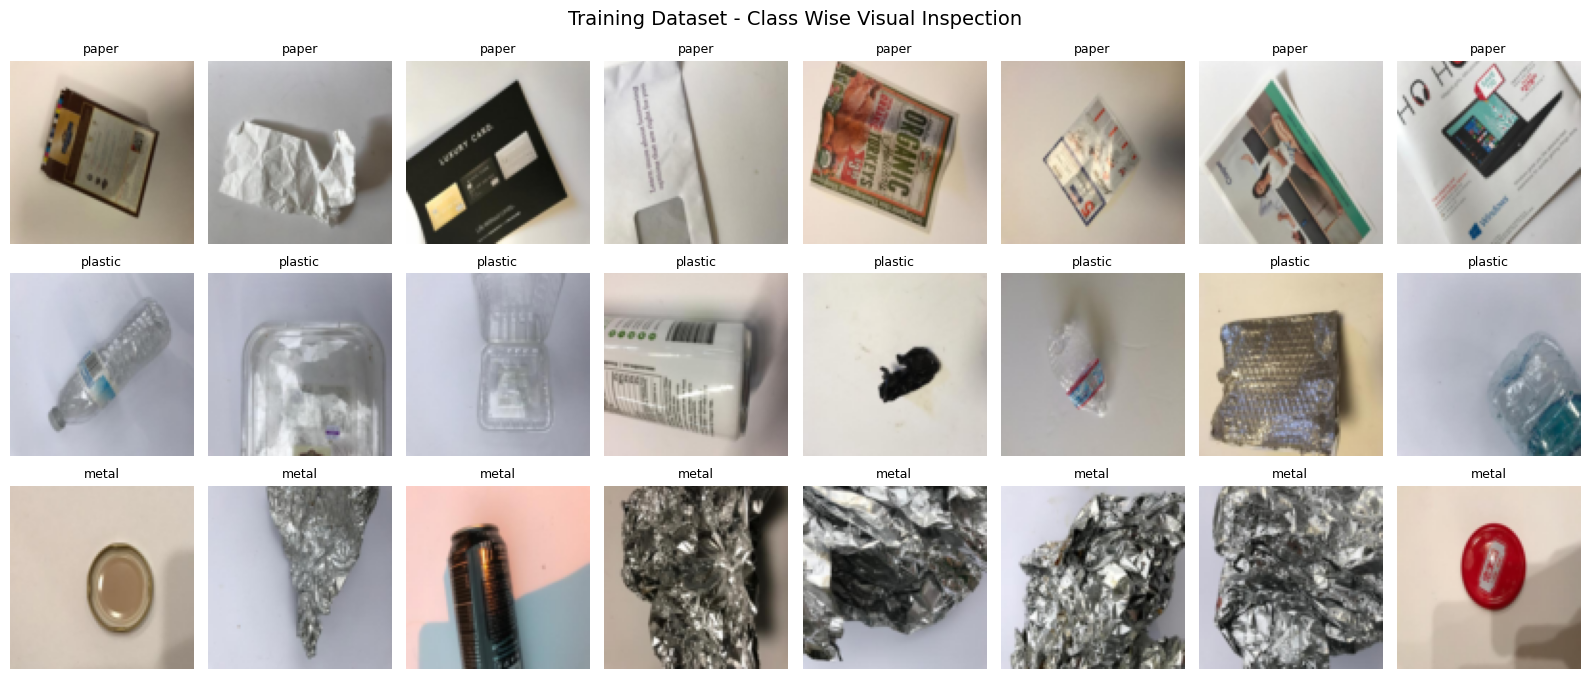

In [22]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(
    3, 8,
    figsize=(16, 7)
)

for class_id, class_name in enumerate(class_names):

    indices = np.where(
        y_train_img == class_id
    )[0]

    # Select 8 different images
    selected = indices[:8]

    for col, idx in enumerate(selected):

        axes[class_id, col].imshow(
            x_train_img[idx]
        )

        axes[class_id, col].set_title(
            class_name,
            fontsize=9
        )

        axes[class_id, col].axis("off")

plt.suptitle(
    "Training Dataset - Class Wise Visual Inspection",
    fontsize=14
)

plt.tight_layout()
plt.show()


# Cell 19 -- Check the lables of the images

CLASS MAPPING
0: paper
1: plastic
2: metal

CLASS DISTRIBUTION

Training:
paper: 210
plastic: 210
metal: 210

Validation:
paper: 45
plastic: 45
metal: 45

Testing:
paper: 45
plastic: 45
metal: 45

IMAGE LABEL VISUAL CHECK


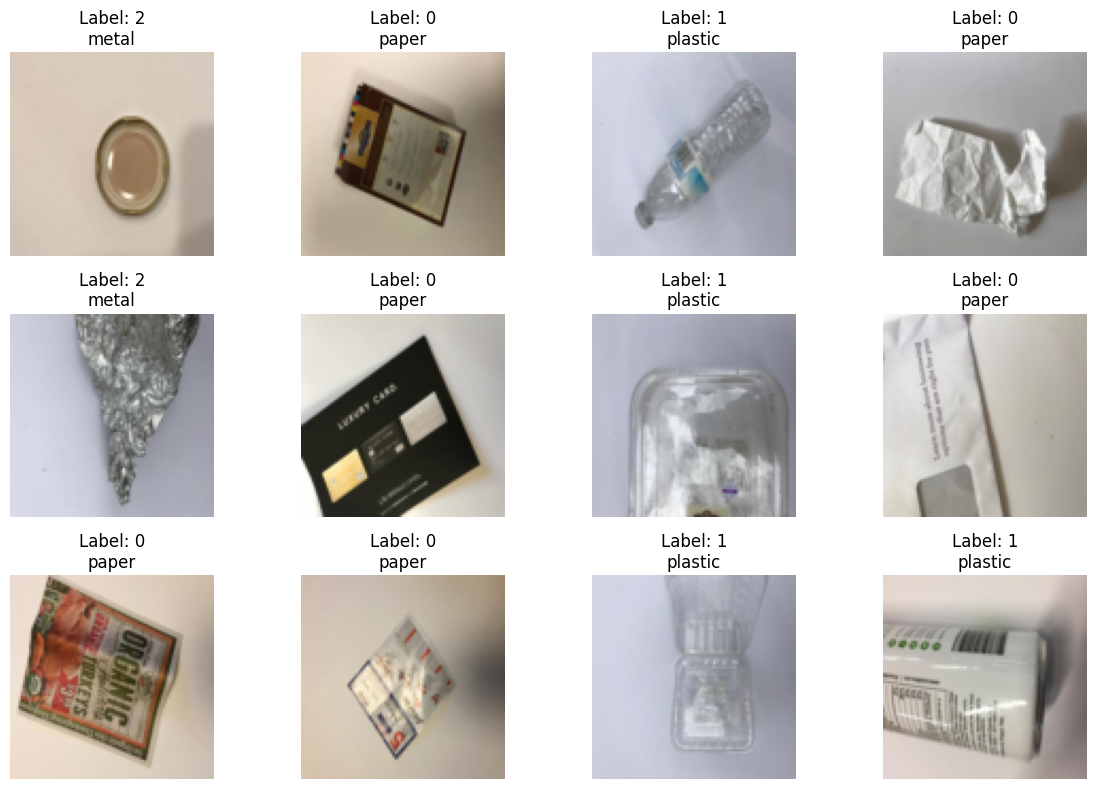

In [23]:
import numpy as np
import matplotlib.pyplot as plt

print("CLASS MAPPING")
for i, name in enumerate(class_names):
    print(f"{i}: {name}")

print("\nCLASS DISTRIBUTION")

for split_name, labels in [
    ("Training", y_train_img),
    ("Validation", y_val_img),
    ("Testing", y_test_img)
]:
    counts = np.bincount(
        labels.astype(int),
        minlength=len(class_names)
    )

    print(f"\n{split_name}:")
    for name, count in zip(class_names, counts):
        print(f"{name}: {count}")

print("\nIMAGE LABEL VISUAL CHECK")

plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)

    plt.imshow(x_train_img[i])

    label = int(y_train_img[i])

    plt.title(
        f"Label: {label}\n{class_names[label]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

# Cell 20 -- Check the test, train & validation *images*

In [24]:
print("Training images:", x_train_img.shape)
print("Validation images:", x_val_img.shape)
print("Test images:", x_test_img.shape)

print("Training labels:", y_train_img.shape)
print("Validation labels:", y_val_img.shape)

print("Image data type:", x_train_img.dtype)
print("Minimum pixel:", x_train_img.min())
print("Maximum pixel:", x_train_img.max())

Training images: (630, 96, 96, 3)
Validation images: (135, 96, 96, 3)
Test images: (135, 96, 96, 3)
Training labels: (630,)
Validation labels: (135,)
Image data type: uint8
Minimum pixel: 0
Maximum pixel: 255


# Cell 21 -- Check the images classification

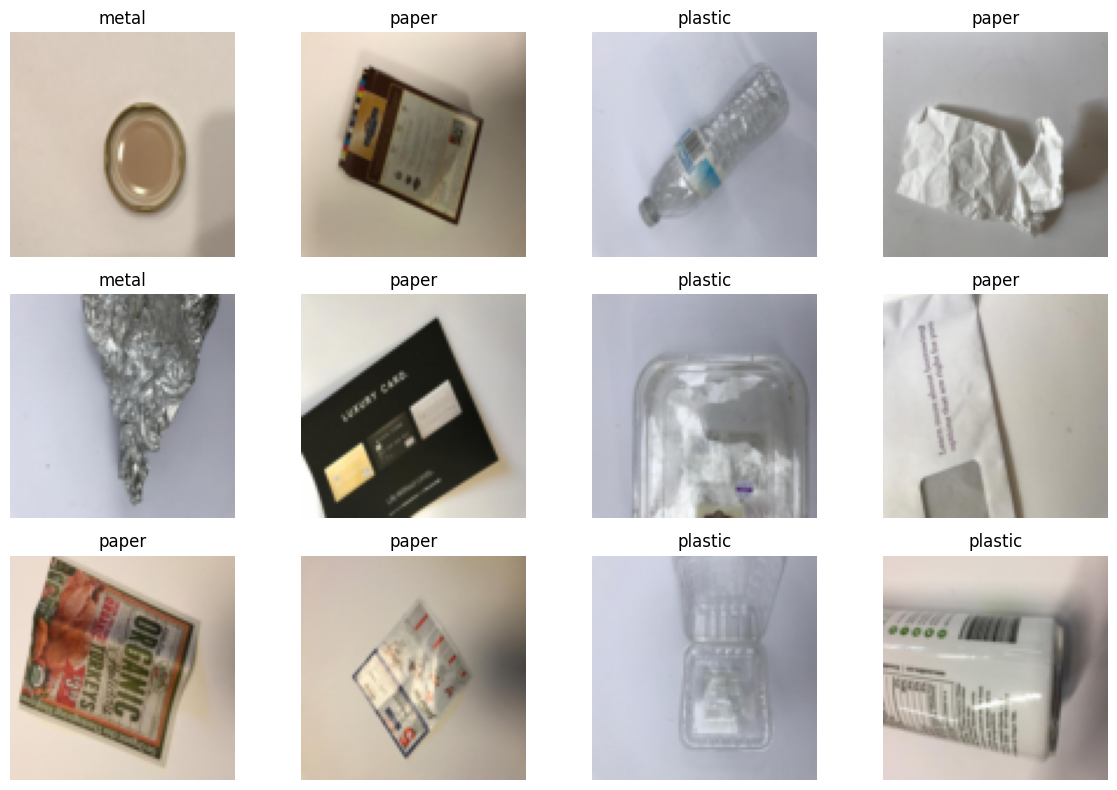

In [25]:

plt.figure(figsize=(12, 8))

for i in range(12):

    plt.subplot(3, 4, i + 1)
    plt.imshow(x_train_img[i])
    label = int(y_train_img[i])
    plt.title(class_names[label])
    plt.axis("off")

plt.tight_layout()
plt.show()


## Cell 22 — Build the assignment's small CNN
**Model Architecture Code Cell:**

> We use the supplied architecture and three-epoch limit. The `Rescaling` layer divides pixels by 255 exactly once. Do not divide the NumPy arrays by 255 again.




In [77]:

import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

image_model = models.Sequential([

    layers.Input(shape=(96, 96, 3)),

    # Mild augmentation
    layers.RandomFlip("horizontal"),

    # Normalize images
    layers.Rescaling(1.0 / 255),

    # Convolution Block 1
    layers.Conv2D(
        16, (3, 3),
        padding="same",
        activation="relu"
    ),
    layers.MaxPooling2D(),

    # Convolution Block 2
    layers.Conv2D(
        32, (3, 3),
        padding="same",
        activation="relu"
    ),
    layers.MaxPooling2D(),

    # Classification
    layers.Flatten(),

    layers.Dense(
        16,
        activation="relu"
    ),

    layers.Dense(
        3,
        activation="softmax"
    )

], name="best_augmented_flatten_cnn.keras")

image_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

image_model.summary()


Model: "best_augmented_flatten_cnn.keras"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │       294,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 300,067 (1.14 MB)

 Trainable params: 300,067 (1.14 MB)

 Non-trainable params: 0 (0.00 B)

# Cell 23 -- CallBack Cell

In [78]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="best_augmented_flatten_cnn.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=0.00001,
    verbose=1
)

## Cell 24 — Train for up to 40 epochs

EarlyStopping monitors validation loss and restores the best weights seen during this short run. It may stop before epoch 3 if validation loss fails to improve. This is a safeguard, not a promise of high accuracy.

In [79]:
history = image_model.fit(
    x_train_img,
    y_train_img,
    validation_data=(x_val_img, y_val_img),
    epochs=40,
    batch_size=32,
    callbacks=[checkpoint, reduce_lr],
    shuffle=True,
    verbose=1
)

Epoch 1/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.3806 - loss: 1.4220
Epoch 1: val_loss improved from None to 1.10734, saving model to best_augmented_flatten_cnn.keras

Epoch 1: finished saving model to best_augmented_flatten_cnn.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 195ms/step - accuracy: 0.3603 - loss: 1.2708 - val_accuracy: 0.3333 - val_loss: 1.1073 - learning_rate: 0.0010
Epoch 2/40
15/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3754 - loss: 1.1011
Epoch 2: val_loss improved from 1.10734 to 1.07984, saving model to best_augmented_flatten_cnn.keras

Epoch 2: finished saving model to best_augmented_flatten_cnn.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.3825 - loss: 1.0964 - val_accuracy: 0.4000 - val_loss: 1.0798 - learning_rate: 0.0010
Epoch 3/40
16/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3487 - loss: 1.0750
Epoch 3: val_loss improved from 1.07984 to 1.04069, saving model to best_augmented_flatten_cnn.keras

Epoch 3: finished saving mod

# Cell 25 -- CNN Model Best Validation Performacnce

In [80]:
best_augmented_model = tf.keras.models.load_model(
    "best_augmented_flatten_cnn.keras"
)

best_epoch = np.argmin(
    history.history["val_loss"]
) + 1

val_loss, val_accuracy = best_augmented_model.evaluate(
    x_val_img,
    y_val_img,
    verbose=1
)

print("Best Epoch:", best_epoch)
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.7852 - loss: 0.6032
Best Epoch: 29
Validation Accuracy: 78.52%
Validation Loss: 0.6032


# Cell 26 -- Check the Model best Accuracies and Losses

In [81]:

import numpy as np
import tensorflow as tf

best_model = tf.keras.models.load_model(
    "best_augmented_flatten_cnn.keras"
)

# Find best validation loss epoch
best_loss_index = np.argmin(
    history.history["val_loss"]
)

best_loss_epoch = best_loss_index + 1

# Find best validation accuracy epoch
best_acc_index = np.argmax(
    history.history["val_accuracy"]
)

best_acc_epoch = best_acc_index + 1

print("Best Validation Loss Epoch:", best_loss_epoch)
print(
    "Best Validation Loss:",
    round(history.history["val_loss"][best_loss_index], 4)
)

print("Best Validation Accuracy Epoch:", best_acc_epoch)
print(
    "Best Validation Accuracy:",
    round(history.history["val_accuracy"][best_acc_index], 4)
)

# Accuracy gap at the best-loss epoch
train_acc = history.history["accuracy"][best_loss_index]
val_acc = history.history["val_accuracy"][best_loss_index]

print(
    "Accuracy gap at best-loss epoch:",
    round(abs(train_acc - val_acc), 4)
)


Best Validation Loss Epoch: 29
Best Validation Loss: 0.6032
Best Validation Accuracy Epoch: 33
Best Validation Accuracy: 0.8
Accuracy gap at best-loss epoch: 0.1402


# Cell 27 -- Plot the CNN MOdel Accuracy and Loss

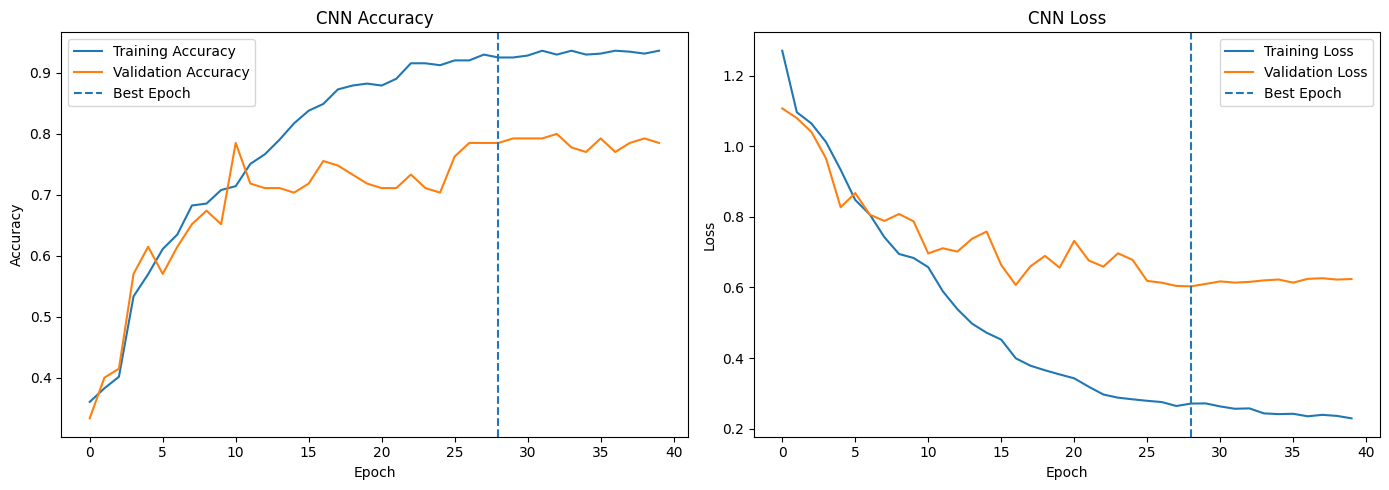

In [82]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Accuracy graph
plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.axvline(
    best_epoch - 1,
    linestyle="--",
    label="Best Epoch"
)

plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    best_epoch - 1,
    linestyle="--",
    label="Best Epoch"
)

plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


## Cell 28 — 2nd Plots of training and validation accuracy/loss

Look at both curves. If training accuracy rises while validation accuracy falls, or training loss falls while validation loss rises, that may indicate overfitting. A small gap is useful only when both scores are meaningful.

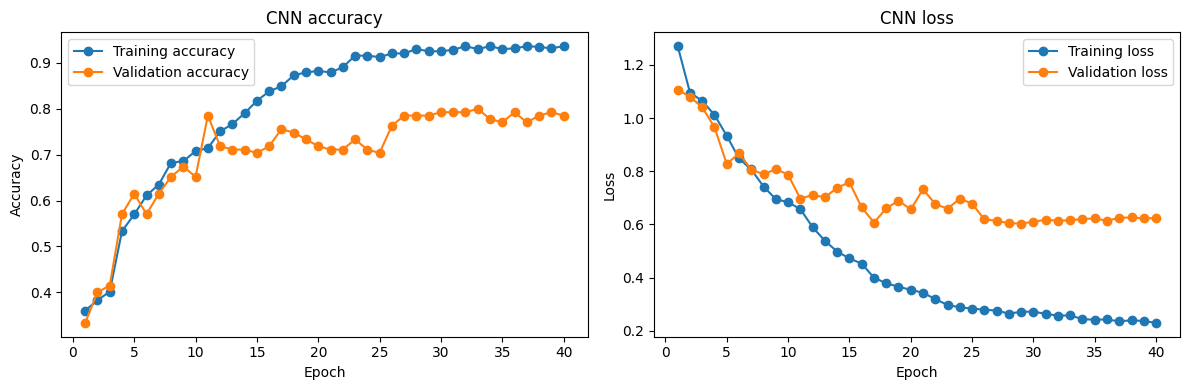

Epochs completed: 40
Final epoch training accuracy: 0.9365
Final epoch validation accuracy: 0.7852
Absolute accuracy gap: 0.1513


In [83]:
hist = history.history
epochs_ran = range(1, len(hist["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_ran, hist["accuracy"], marker="o", label="Training accuracy")
axes[0].plot(epochs_ran, hist["val_accuracy"], marker="o", label="Validation accuracy")
axes[0].set_title("CNN accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(epochs_ran, hist["loss"], marker="o", label="Training loss")
axes[1].plot(epochs_ran, hist["val_loss"], marker="o", label="Validation loss")
axes[1].set_title("CNN loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig(REPORTS_DIR / "cnn_training_curves.png", dpi=160, bbox_inches="tight")
plt.show()

print("Epochs completed:", len(hist["loss"]))
print("Final epoch training accuracy:", round(hist["accuracy"][-1], 4))
print("Final epoch validation accuracy:", round(hist["val_accuracy"][-1], 4))
print("Absolute accuracy gap:", round(abs(hist["accuracy"][-1] - hist["val_accuracy"][-1]), 4))

# Cell 29 -- Check the validation Confusion Matrix

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step
VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

       paper     0.7347    0.8000    0.7660        45
     plastic     0.7872    0.8222    0.8043        45
       metal     0.8462    0.7333    0.7857        45

    accuracy                         0.7852       135
   macro avg     0.7894    0.7852    0.7853       135
weighted avg     0.7894    0.7852    0.7853       135



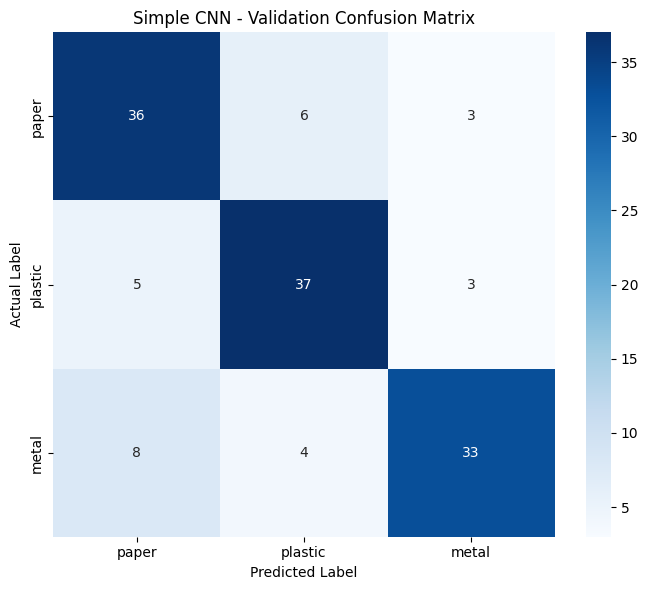

In [84]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Load the best original Simple CNN
best_simple_model = tf.keras.models.load_model(
    "best_augmented_flatten_cnn.keras"
)

# Predict validation images
y_pred_prob = best_simple_model.predict(
    x_val_img,
    verbose=1
)

y_pred = np.argmax(y_pred_prob, axis=1)

# Classification report
print("VALIDATION CLASSIFICATION REPORT")

print(
    classification_report(
        y_val_img,
        y_pred,
        labels=[0, 1, 2],
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_val_img,
    y_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Simple CNN - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

# Cell 30 -- Visual Inspection of Misclassified Validation

In [85]:

import numpy as np
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# 1. Load the best saved CNN model
best_simple_model = tf.keras.models.load_model(
    "best_augmented_flatten_cnn.keras"
)

# 2. Generate predictions
y_pred_prob = best_simple_model.predict(
    x_val_img,
    verbose=1
)

y_pred = np.argmax(y_pred_prob, axis=1)

# 3. Calculate prediction confidence
predicted_confidence = np.max(y_pred_prob, axis=1) * 100

# 4. Find correct and incorrect predictions
wrong_indices = np.where(y_pred != y_val_img)[0]
correct_indices = np.where(y_pred == y_val_img)[0]

print("\n" + "=" * 65)
print("DETAILED CNN VALIDATION ANALYSIS")
print("=" * 65)

print("\nTOTAL VALIDATION IMAGES:", len(y_val_img))
print("CORRECT PREDICTIONS:", len(correct_indices))
print("INCORRECT PREDICTIONS:", len(wrong_indices))
print("VALIDATION ACCURACY:",
      round(len(correct_indices) / len(y_val_img) * 100, 2), "%")

# 5. Classification report
print("\n\nCLASSIFICATION REPORT")

print(classification_report(
    y_val_img,
    y_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    digits=4,
    zero_division=0
))

# 6. Confusion matrix
cm = confusion_matrix(
    y_val_img,
    y_pred,
    labels=[0, 1, 2]
)

print("\nCONFUSION MATRIX")
print("Rows = Actual | Columns = Predicted")
print("Class order:", class_names)
print(cm)

# 7. Class-wise prediction analysis
print("\n\nCLASS-WISE ERROR ANALYSIS")

for class_id, class_name in enumerate(class_names):

    class_indices = np.where(y_val_img == class_id)[0]

    class_wrong = np.where(
        (y_val_img == class_id) &
        (y_pred != class_id)
    )[0]

    class_correct = np.where(
        (y_val_img == class_id) &
        (y_pred == class_id)
    )[0]

    print(f"\n{class_name.upper()}")
    print("Total images:", len(class_indices))
    print("Correct:", len(class_correct))
    print("Incorrect:", len(class_wrong))

    if len(class_wrong) > 0:
        print("Incorrectly predicted as:")

        for predicted_id in range(len(class_names)):
            count = np.sum(y_pred[class_wrong] == predicted_id)

            if count > 0:
                print(
                    f"  {class_names[predicted_id]}: {count}"
                )

# 8. Confidence analysis
print("\n\nCONFIDENCE ANALYSIS")

if len(correct_indices) > 0:
    print(
        "Average confidence on correct predictions:",
        round(np.mean(predicted_confidence[correct_indices]), 2),
        "%"
    )

if len(wrong_indices) > 0:
    print(
        "Average confidence on incorrect predictions:",
        round(np.mean(predicted_confidence[wrong_indices]), 2),
        "%"
    )

# 9. Detailed list of all misclassified images
print("\n\nALL MISCLASSIFIED IMAGE DETAILS")
print("-" * 65)

print(
    f"{'Index':<8} {'Actual':<12} "
    f"{'Predicted':<12} {'Confidence':<12}"
)

for idx in wrong_indices:

    actual = class_names[int(y_val_img[idx])]
    predicted = class_names[int(y_pred[idx])]
    confidence = predicted_confidence[idx]

    print(
        f"{idx:<8} {actual:<12} "
        f"{predicted:<12} {confidence:.2f}%"
    )

# 10. High-confidence incorrect predictions
print("\n\nHIGH-CONFIDENCE INCORRECT PREDICTIONS")
print("(Confidence >= 80%)")

high_confidence_errors = [
    idx for idx in wrong_indices
    if predicted_confidence[idx] >= 80
]

if len(high_confidence_errors) > 0:

    for idx in high_confidence_errors:
        print(
            f"Index {idx}: "
            f"Actual={class_names[int(y_val_img[idx])]}, "
            f"Predicted={class_names[int(y_pred[idx])]}, "
            f"Confidence={predicted_confidence[idx]:.2f}%"
        )

else:
    print("No high-confidence errors found.")

# 11. Low-confidence correct predictions
print("\n\nLOW-CONFIDENCE CORRECT PREDICTIONS")
print("(Confidence < 60%)")

low_confidence_correct = [
    idx for idx in correct_indices
    if predicted_confidence[idx] < 60
]

if len(low_confidence_correct) > 0:

    for idx in low_confidence_correct:
        print(
            f"Index {idx}: "
            f"Actual={class_names[int(y_val_img[idx])]}, "
            f"Confidence={predicted_confidence[idx]:.2f}%"
        )

else:
    print("No low-confidence correct predictions found.")

print("\n" + "=" * 65)
print("ANALYSIS COMPLETED")
print("=" * 65)


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step

DETAILED CNN VALIDATION ANALYSIS

TOTAL VALIDATION IMAGES: 135
CORRECT PREDICTIONS: 106
INCORRECT PREDICTIONS: 29
VALIDATION ACCURACY: 78.52 %


CLASSIFICATION REPORT
              precision    recall  f1-score   support

       paper     0.7347    0.8000    0.7660        45
     plastic     0.7872    0.8222    0.8043        45
       metal     0.8462    0.7333    0.7857        45

    accuracy                         0.7852       135
   macro avg     0.7894    0.7852    0.7853       135
weighted avg     0.7894    0.7852    0.7853       135


CONFUSION MATRIX
Rows = Actual | Columns = Predicted
Class order: ['paper', 'plastic', 'metal']
[[36  6  3]
 [ 5 37  3]
 [ 8  4 33]]


CLASS-WISE ERROR ANALYSIS

PAPER
Total images: 45
Correct: 36
Incorrect: 9
Incorrectly predicted as:
  plastic: 6
  metal: 3

PLASTIC
Total images: 45
Correct: 37
Incorrect: 8
Incorrectly predicted as:
  paper: 5
  metal: 3

METAL
Total images: 45
Correct: 33
Incorrect: 12
In

# Cell 31 -- textCNN High Confidence Error Investigation

In [86]:

import numpy as np
import tensorflow as tf

# Load best original CNN checkpoint
best_simple_model = tf.keras.models.load_model(
    "best_augmented_flatten_cnn.keras"
)

# Check validation dataset
print("=" * 65)
print("VALIDATION DATASET VERIFICATION")
print("=" * 65)

print("Image shape:", x_val_img.shape)
print("Label shape:", y_val_img.shape)
print("Image dtype:", x_val_img.dtype)
print("Minimum pixel:", np.min(x_val_img))
print("Maximum pixel:", np.max(x_val_img))

print("\nClass mapping:")
for i, name in enumerate(class_names):
    print(i, ":", name)

# Generate predictions
probabilities = best_simple_model.predict(
    x_val_img,
    verbose=0
)

predictions = np.argmax(probabilities, axis=1)

# Find high-confidence incorrect predictions
wrong_indices = np.where(
    predictions != y_val_img
)[0]

print("\n" + "=" * 65)
print("HIGH CONFIDENCE INCORRECT PREDICTIONS")
print("=" * 65)

for idx in wrong_indices:

    confidence = float(
        np.max(probabilities[idx]) * 100
    )

    if confidence >= 80:

        print("\nImage Index:", int(idx))
        print("Actual:", class_names[int(y_val_img[idx])])
        print("Predicted:", class_names[int(predictions[idx])])
        print("Confidence:", round(confidence, 2), "%")

        print("All class probabilities:")

        for class_id, class_name in enumerate(class_names):
            print(
                class_name,
                ":",
                round(
                    float(probabilities[idx][class_id]) * 100,
                    2
                ),
                "%"
            )

# Check prediction distribution
print("\n" + "=" * 65)
print("PREDICTED CLASS DISTRIBUTION")
print("=" * 65)

for i, name in enumerate(class_names):
    print(
        name,
        ":",
        int(np.sum(predictions == i))
    )

# Verify model output dimensions
print("\nModel output shape:", probabilities.shape)

print("\nINVESTIGATION COMPLETED")


VALIDATION DATASET VERIFICATION
Image shape: (135, 96, 96, 3)
Label shape: (135,)
Image dtype: uint8
Minimum pixel: 0
Maximum pixel: 255

Class mapping:
0 : paper
1 : plastic
2 : metal



HIGH CONFIDENCE INCORRECT PREDICTIONS

Image Index: 9
Actual: paper
Predicted: metal
Confidence: 96.78 %
All class probabilities:
paper : 3.2 %
plastic : 0.02 %
metal : 96.78 %

Image Index: 51
Actual: paper
Predicted: metal
Confidence: 96.9 %
All class probabilities:
paper : 3.1 %
plastic : 0.0 %
metal : 96.9 %

Image Index: 73
Actual: paper
Predicted: metal
Confidence: 89.16 %
All class probabilities:
paper : 2.88 %
plastic : 7.96 %
metal : 89.16 %

PREDICTED CLASS DISTRIBUTION
paper : 49
plastic : 47
metal : 39

Model output shape: (135, 3)

INVESTIGATION COMPLETED


In [89]:
# =====================================================
# SAVE BEST AUGMENTED CNN MODEL TO GOOGLE DRIVE
# =====================================================

from pathlib import Path
import json
import tensorflow as tf

# Make sure the model directory exists
MODELS_DIR = Path(MODELS_DIR)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Load the best validation-loss checkpoint from the root directory where it was saved
image_model = tf.keras.models.load_model(
    "best_augmented_flatten_cnn.keras"
)

# Save a standard final copy to your Google Drive
image_model.save(MODELS_DIR / "images.keras")

# Save model metadata
image_metadata = {
    "image_shape": list(meta["image_shape"]),
    "class_names": list(class_names),
    "input_dtype": "uint8",
    "input_pixel_range": [0, 255],
    "rescaling_in_model": "1./255",
    "architecture": "augmented_flatten_cnn",
    "checkpoint": "best_augmented_flatten_cnn.keras",
    "model_file": "images.keras"
}

(MODELS_DIR / "image_metadata.json").write_text(
    json.dumps(image_metadata, indent=2)
)

print("CNN model successfully saved!")
print("Model location:", MODELS_DIR / "images.keras")
print("Metadata location:", MODELS_DIR / "image_metadata.json")

CNN model successfully saved!
Model location: /content/drive/MyDrive/Community_Waste_Project/source/AI_for_Everyone_Ready_Datasets/Project_03/models/images.keras
Metadata location: /content/drive/MyDrive/Community_Waste_Project/source/AI_for_Everyone_Ready_Datasets/Project_03/models/image_metadata.json


In [90]:
# Verify saved CNN model

saved_model_path = MODELS_DIR / "images.keras"

assert saved_model_path.exists(), "Model file not found!"

print("Model exists:", saved_model_path.exists())
print("Model size (MB):", round(
    saved_model_path.stat().st_size / (1024 * 1024), 2
))

# Load model again to verify
loaded_model = tf.keras.models.load_model(saved_model_path)

print("Model loaded successfully!")
loaded_model.summary()

Model exists: True
Model size (MB): 3.47
Model loaded successfully!


Model: "best_augmented_flatten_cnn.keras"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │       294,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 900,203 (3.43 MB)

 Trainable params: 300,067 (1.14 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 600,136 (2.29 MB)

## Cell 32 — Final CNN test evaluation

Use the held-out test images once for final evaluation. Keep the result separate from the tabular Decision Tree metrics.

CNN test loss: 0.5420
CNN test accuracy: 0.7926
CNN test macro F1: 0.7905
              precision    recall  f1-score   support

       paper       0.77      0.91      0.84        45
     plastic       0.76      0.78      0.77        45
       metal       0.86      0.69      0.77        45

    accuracy                           0.79       135
   macro avg       0.80      0.79      0.79       135
weighted avg       0.80      0.79      0.79       135



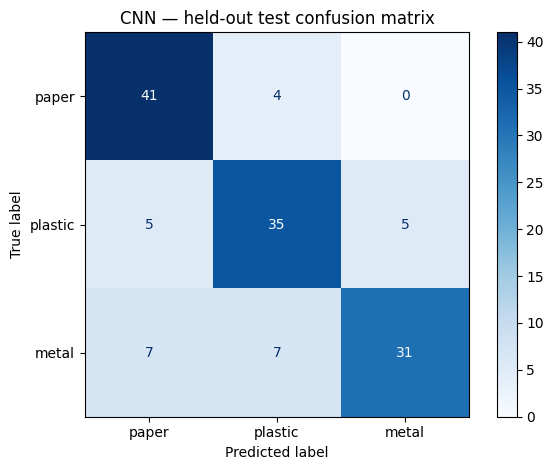

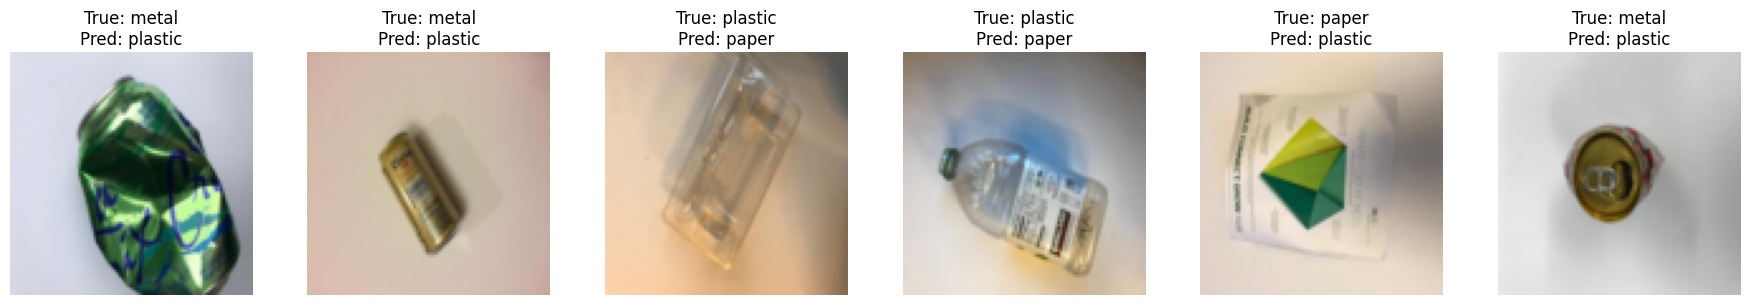

In [ ]:
# Load the best saved augmented CNN model checkpoint
import tensorflow as tf
import numpy as np
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

image_model = tf.keras.models.load_model("best_augmented_flatten_cnn.keras")

test_loss, test_accuracy = image_model.evaluate(x_test_img, y_test_img, verbose=0)
test_probabilities = image_model.predict(x_test_img, verbose=0)
test_predictions = np.argmax(test_probabilities, axis=1)

cnn_macro_f1 = f1_score(y_test_img, test_predictions, average="macro", zero_division=0)
print(f"CNN test loss: {test_loss:.4f}")
print(f"CNN test accuracy: {test_accuracy:.4f}")
print(f"CNN test macro F1: {cnn_macro_f1:.4f}")
print(classification_report(
    y_test_img, test_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_img, test_predictions,
    labels=list(range(len(class_names))),
    display_labels=class_names,
    cmap="Blues"
)
plt.title("CNN — held-out test confusion matrix")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "cnn_test_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

wrong = np.where(test_predictions != y_test_img)[0][:6]
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(3 * len(wrong), 3))
    if len(wrong) == 1:
        axes = [axes]
    for ax, idx in zip(axes, wrong):
        ax.imshow(x_test_img[idx])
        ax.set_title(f"True: {class_names[int(y_test_img[idx])] }\nPred: {class_names[int(test_predictions[idx])]}")
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(REPORTS_DIR / "cnn_test_misclassifications.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("No test misclassifications in this run.")

In [95]:

from pathlib import Path

# Project models directory
MODELS_DIR = Path(
    "/content/drive/MyDrive/Community_Waste_Project/"
    "source/AI_for_Everyone_Ready_Datasets/Project_03/models"
)

print("MODEL DIRECTORY:", MODELS_DIR)
print("Directory exists:", MODELS_DIR.exists())

if MODELS_DIR.exists():
    print("\n========== SAVED FILES ==========")

    for file in sorted(MODELS_DIR.rglob("*")):
        if file.is_file():
            size_mb = file.stat().st_size / (1024 * 1024)

            print(
                f"{file.name:<35} "
                f"| {size_mb:.2f} MB "
                f"| {file}"
            )
else:
    print("ERROR: Models directory not found!")


MODEL DIRECTORY: /content/drive/MyDrive/Community_Waste_Project/source/AI_for_Everyone_Ready_Datasets/Project_03/models
Directory exists: True

========== SAVED FILES ==========
baseline.joblib                     | 0.00 MB | /content/drive/MyDrive/Community_Waste_Project/source/AI_for_Everyone_Ready_Datasets/Project_03/models/baseline.joblib
cluster_metadata.json               | 0.00 MB | /content/drive/MyDrive/Community_Waste_Project/source/AI_for_Everyone_Ready_Datasets/Project_03/models/cluster_metadata.json
clusters.joblib                     | 0.00 MB | /content/drive/MyDrive/Community_Waste_Project/source/AI_for_Everyone_Ready_Datasets/Project_03/models/clusters.joblib
image_metadata.json                 | 0.00 MB | /content/drive/MyDrive/Community_Waste_Project/source/AI_for_Everyone_Ready_Datasets/Project_03/models/image_metadata.json
images.keras                        | 3.47 MB | /content/drive/MyDrive/Community_Waste_Project/source/AI_for_Everyone_Ready_Datasets/Project_03/

In [96]:

import joblib
import json
import tensorflow as tf
from pathlib import Path

print("========== MODEL VERIFICATION ==========")

# 1. Verify CNN
cnn_path = MODELS_DIR / "images.keras"

cnn = tf.keras.models.load_model(cnn_path)

print("\nCNN MODEL:")
print("Loaded successfully")
print("Input:", cnn.input_shape)
print("Output:", cnn.output_shape)

# 2. Verify Scikit-learn models
for filename in [
    "baseline.joblib",
    "clusters.joblib",
    "supervised.joblib"
]:
    path = MODELS_DIR / filename

    print(f"\n{filename}:")

    try:
        model = joblib.load(path)

        print("Loaded successfully")
        print("Model type:", type(model).__name__)

        if hasattr(model, "n_clusters"):
            print("Number of clusters:", model.n_clusters)

        if hasattr(model, "classes_"):
            print("Classes:", model.classes_)

    except Exception as e:
        print("ERROR:", str(e))

# 3. Verify metadata JSON files
for filename in [
    "image_metadata.json",
    "cluster_metadata.json",
    "supervised_metadata.json"
]:
    path = MODELS_DIR / filename

    print(f"\n{filename}:")

    try:
        with open(path, "r") as f:
            metadata = json.load(f)

        print("Valid JSON metadata")
        print(metadata)

    except Exception as e:
        print("ERROR:", str(e))

print("\n========== VERIFICATION COMPLETED ==========")


========== MODEL VERIFICATION ==========

CNN MODEL:
Loaded successfully
Input: (None, 96, 96, 3)
Output: (None, 3)

baseline.joblib:
Loaded successfully
Model type: DummyClassifier
Classes: [0 1]

clusters.joblib:
Loaded successfully
Model type: Pipeline

supervised.joblib:
Loaded successfully
Model type: Pipeline
Classes: [0 1]

image_metadata.json:
Valid JSON metadata
{'image_shape': [96, 96, 3], 'class_names': ['paper', 'plastic', 'metal'], 'input_dtype': 'uint8', 'input_pixel_range': [0, 255], 'rescaling_in_model': '1./255', 'architecture': 'augmented_flatten_cnn', 'checkpoint': 'best_augmented_flatten_cnn.keras', 'model_file': 'images.keras'}

cluster_metadata.json:
Valid JSON metadata
{'features': ['fill_pct', 'days_since_collection', 'footfall', 'capacity_l'], 'n_clusters': 3, 'random_state': 42, 'group_descriptions': {'0': 'Higher average fill with comparatively lower footfall', '1': 'Lower average fill with higher footfall', '2': 'Higher average fill and higher average footfa

# Cell 33 --

> # 1. Build MobileNetV2 Transfer Learning Model





In [94]:

# MobileNetV2 Transfer Learning Model

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Pretrained MobileNetV2 model
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(160, 160, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Build complete model
inputs = layers.Input(shape=(96, 96, 3))

# Resize images
x = layers.Resizing(160, 160)(inputs)

# MobileNetV2 preprocessing: 0-255 to -1 to +1
x = layers.Rescaling(scale=1./127.5, offset=-1)(x)

# Extract pretrained features
x = base_model(x, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.15)(x)

outputs = layers.Dense(3, activation="softmax")(x)

mobilenet_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="mobilenetv2_waste_classifier"
)

# Compile
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "mobilenetv2_waste_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,163 (8.93 MB)

 Trainable params: 82,179 (321.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# Cell 34 --
# 2. MobileNetV2 Training Callbacks

In [97]:

# Save the best MobileNetV2 model
mobilenet_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="best_mobilenetv2.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

# Reduce learning rate when validation loss stops improving
mobilenet_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)


# Cell 35 --
# 3. Train MobileNetV2 Model

In [98]:

mobilenet_history = mobilenet_model.fit(
    x_train_img,
    y_train_img,
    validation_data=(x_val_img, y_val_img),
    epochs=30,
    batch_size=32,
    callbacks=[
        mobilenet_checkpoint,
        mobilenet_reduce_lr
    ],
    shuffle=True,
    verbose=1
)


Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 872ms/step - accuracy: 0.5624 - loss: 0.9909
Epoch 1: val_loss improved from None to 0.40687, saving model to best_mobilenetv2.keras

Epoch 1: finished saving model to best_mobilenetv2.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.6254 - loss: 0.8788 - val_accuracy: 0.8519 - val_loss: 0.4069 - learning_rate: 0.0010
Epoch 2/30
18/20 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8647 - loss: 0.3708
Epoch 2: val_loss improved from 0.40687 to 0.32981, saving model to best_mobilenetv2.keras

Epoch 2: finished saving model to best_mobilenetv2.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 29s 49ms/step - accuracy: 0.8429 - loss: 0.3945 - val_accuracy: 0.8963 - val_loss: 0.3298 - learning_rate: 0.0010
Epoch 3/30
17/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9369 - loss: 0.2188
Epoch 3: val_loss did not improve from 0.32981
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9095 - loss: 0.2605 - val_accuracy: 0.8667 - val_loss: 0.3519 - lear

#Cell 36 --
# 4. Load Best MobileNetV2 Checkpoint

In [99]:

best_mobilenet_model = tf.keras.models.load_model(
    "best_mobilenetv2.keras"
)

val_loss, val_accuracy = best_mobilenet_model.evaluate(
    x_val_img,
    y_val_img,
    verbose=0
)

print("MobileNetV2 Validation Accuracy:",
      round(val_accuracy * 100, 2), "%")

print("MobileNetV2 Validation Loss:",
      round(val_loss, 4))


MobileNetV2 Validation Accuracy: 93.33 %
MobileNetV2 Validation Loss: 0.2315


# Cell 37 --
# 5. Compare Simple CNN vs MobileNetV2

In [100]:

# Evaluate original best Simple CNN
best_simple_model = tf.keras.models.load_model(
    "best_augmented_flatten_cnn.keras"
)

simple_loss, simple_accuracy = best_simple_model.evaluate(
    x_val_img, y_val_img, verbose=0
)

# Evaluate MobileNetV2
mobile_loss, mobile_accuracy = best_mobilenet_model.evaluate(
    x_val_img, y_val_img, verbose=0
)

comparison = pd.DataFrame({
    "Model": ["Original Simple CNN", "MobileNetV2"],
    "Validation Accuracy (%)": [
        simple_accuracy * 100,
        mobile_accuracy * 100
    ],
    "Validation Loss": [
        simple_loss,
        mobile_loss
    ]
})

display(comparison)


,Model,Validation Accuracy (%),Validation Loss
0,Original Simple CNN,78.518516,0.603150
1,MobileNetV2,93.333334,0.231462


# Cell 38--
# 6. Model class wise performance

In [101]:

from sklearn.metrics import classification_report, confusion_matrix

val_predictions = best_mobilenet_model.predict(
    x_val_img,
    verbose=0
)

y_pred = np.argmax(val_predictions, axis=1)

print("Classification Report:")
print(classification_report(
    y_val_img,
    y_pred,
    target_names=class_names,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_val_img, y_pred))


Classification Report:
              precision    recall  f1-score   support

       paper     0.9767    0.9333    0.9545        45
     plastic     0.8462    0.9778    0.9072        45
       metal     1.0000    0.8889    0.9412        45

    accuracy                         0.9333       135
   macro avg     0.9410    0.9333    0.9343       135
weighted avg     0.9410    0.9333    0.9343       135

Confusion Matrix:
[[42  3  0]
 [ 1 44  0]
 [ 0  5 40]]


# Cell 39 --
# 7. Final MobileNetV2 Test Set Evaluation

In [102]:

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Load the selected best model
best_mobilenet_model = tf.keras.models.load_model(
    "best_mobilenetv2.keras"
)

# Evaluate on completely unseen test images
test_loss, test_accuracy = best_mobilenet_model.evaluate(
    x_test_img,
    y_test_img,
    verbose=1
)

print("\nFinal Test Accuracy:",
      round(test_accuracy * 100, 2), "%")

print("Final Test Loss:",
      round(test_loss, 4))

# Generate predictions
test_predictions = best_mobilenet_model.predict(
    x_test_img,
    verbose=0
)

y_test_pred = np.argmax(test_predictions, axis=1)

print("\nClassification Report:")
print(classification_report(
    y_test_img,
    y_test_pred,
    target_names=class_names,
    digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_img,
    y_test_pred
))


5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 576ms/step - accuracy: 0.9185 - loss: 0.2422

Final Test Accuracy: 91.85 %
Final Test Loss: 0.2422

Classification Report:
              precision    recall  f1-score   support

       paper     0.9524    0.8889    0.9195        45
     plastic     0.8750    0.9333    0.9032        45
       metal     0.9333    0.9333    0.9333        45

    accuracy                         0.9185       135
   macro avg     0.9202    0.9185    0.9187       135
weighted avg     0.9202    0.9185    0.9187       135


Confusion Matrix:
[[40  4  1]
 [ 1 42  2]
 [ 1  2 42]]


# Cell 40 -- Save final MobileNetV2 test results in permanent JSON file

In [103]:

# Save MobileNetV2 Final Test Metrics

from sklearn.metrics import f1_score

mobilenet_test_macro_f1 = f1_score(
    y_test_img,
    y_test_pred,
    average="macro",
    zero_division=0
)

mobilenet_test_results = {
    "model": "MobileNetV2",
    "test_accuracy": float(test_accuracy),
    "test_loss": float(test_loss),
    "test_macro_f1": float(mobilenet_test_macro_f1),
    "test_images": int(len(y_test_img)),
    "class_names": class_names
}

(REPORTS_DIR / "mobilenetv2_test_metrics.json").write_text(
    json.dumps(mobilenet_test_results, indent=4)
)

print("MobileNetV2 test metrics saved.")
print(json.dumps(mobilenet_test_results, indent=4))


MobileNetV2 test metrics saved.
{
    "model": "MobileNetV2",
    "test_accuracy": 0.9185185432434082,
    "test_loss": 0.2422379106283188,
    "test_macro_f1": 0.9186997898900012,
    "test_images": 135,
    "class_names": [
        "paper",
        "plastic",
        "metal"
    ]
}


# Cell 41 --
# 8. Predict Individual Unseen Test Images

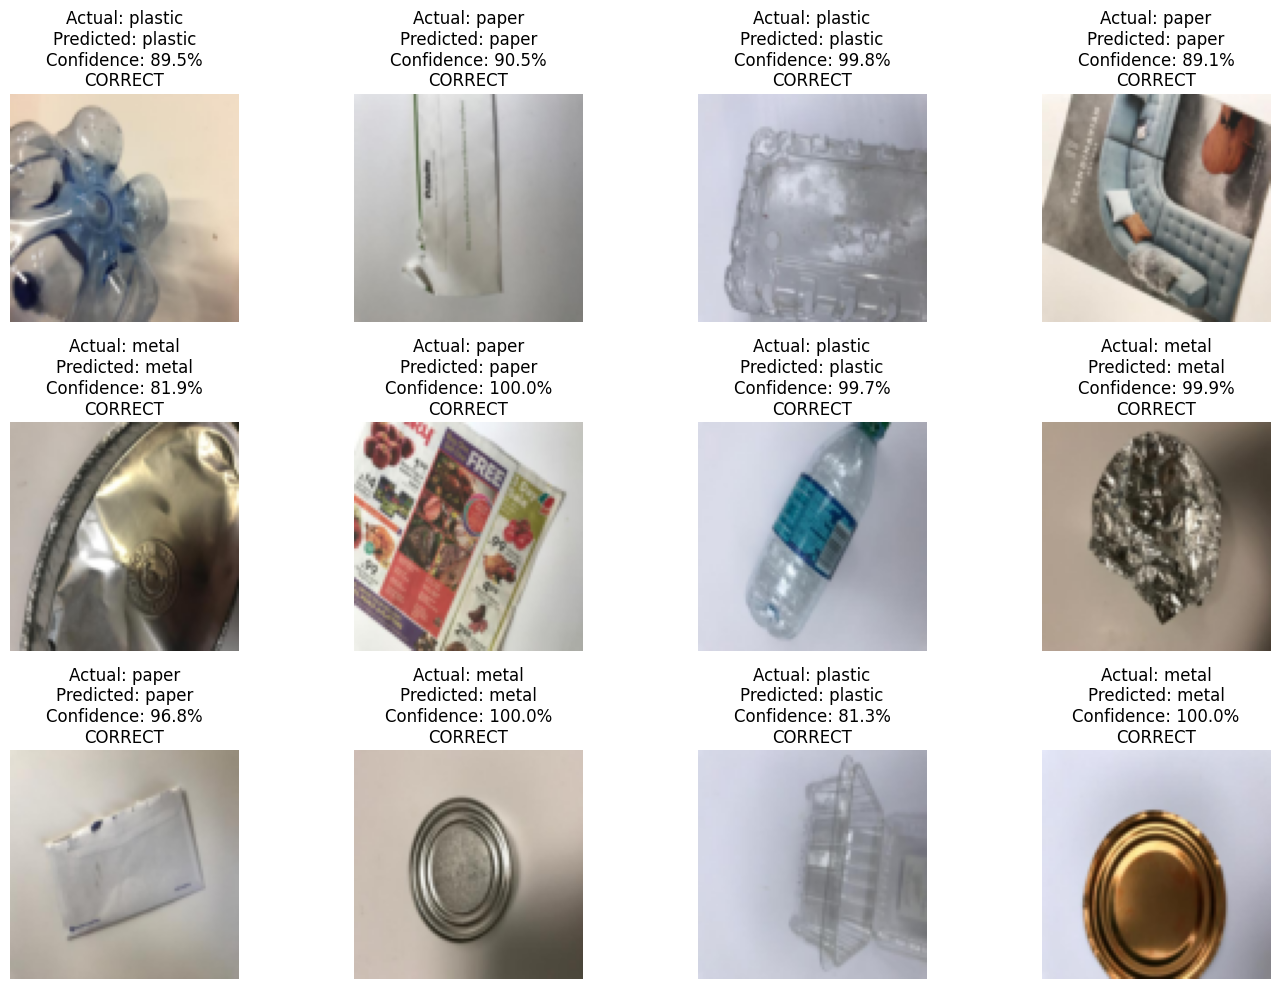

In [104]:

import matplotlib.pyplot as plt

# Display 12 test images with predictions
num_images = 12

indices = np.random.choice(
    len(x_test_img),
    size=num_images,
    replace=False
)

plt.figure(figsize=(14, 10))

for plot_num, idx in enumerate(indices):
    image = x_test_img[idx]

    probabilities = best_mobilenet_model.predict(
        np.expand_dims(image, axis=0),
        verbose=0
    )[0]

    predicted_index = np.argmax(probabilities)
    actual_index = int(y_test_img[idx])

    predicted_class = class_names[predicted_index]
    actual_class = class_names[actual_index]

    confidence = probabilities[predicted_index] * 100

    plt.subplot(3, 4, plot_num + 1)
    plt.imshow(image)

    result = "CORRECT" if predicted_index == actual_index else "WRONG"

    plt.title(
        f"Actual: {actual_class}\n"
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence:.1f}%\n"
        f"{result}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


# Cell 42 --
# 9. Upload and Predict Your Own Waste Image

Saving images (2).jpg to images (2) (1).jpg


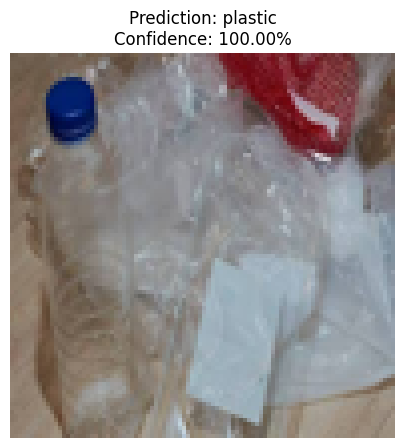

Image: images (2) (1).jpg
Predicted Material: plastic
Confidence: 100.0 %
All Class Probabilities:
paper: 0.00%
plastic: 100.00%
metal: 0.00%


In [108]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Upload an image from your computer
uploaded = files.upload()

for filename in uploaded.keys():

    # Open and convert image to RGB
    img = Image.open(filename).convert("RGB")

    # Resize to the model's original input size
    img = img.resize((96, 96))

    # Convert to numpy array (uint8, 0-255)
    img_array = np.array(img, dtype=np.uint8)

    # Predict
    probabilities = best_mobilenet_model.predict(
        np.expand_dims(img_array, axis=0),
        verbose=0
    )[0]

    predicted_index = np.argmax(probabilities)
    predicted_class = class_names[predicted_index]
    confidence = probabilities[predicted_index] * 100

    # Display image and result
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.show()

    print("Image:", filename)
    print("Predicted Material:", predicted_class)
    print("Confidence:", round(confidence, 2), "%")
    print("All Class Probabilities:")

    for class_name, probability in zip(class_names, probabilities):
        print(f"{class_name}: {probability * 100:.2f}%")


# Cell 43 -- Save Model MobileNetV2

In [110]:
# Load the best validation-loss checkpoint from the local working directory
best_mobilenet = tf.keras.models.load_model(
    "best_mobilenetv2.keras"
)

# Save final model using a permanent filename in Google Drive
final_mobilenet_path = MODELS_DIR / "mobilenetv2_waste.keras"
best_mobilenet.save(final_mobilenet_path)

# Save metadata
mobilenet_metadata = {
    "architecture": "MobileNetV2",
    "image_shape": [96, 96, 3],
    "class_names": ["paper", "plastic", "metal"],
    "input_dtype": "uint8",
    "input_pixel_range": [0, 255],
    "preprocessing": "Rescaling to [-1, 1]",
    "base_model_weights": "ImageNet",
    "base_model_trainable": False,
    "epochs_requested": 30,
    "epochs_completed": len(mobilenet_history.history["loss"]),
    "model_file": "mobilenetv2_waste.keras"
}

with open(MODELS_DIR / "mobilenetv2_metadata.json", "w") as f:
    json.dump(mobilenet_metadata, f, indent=2)

print("MobileNetV2 successfully saved!")
print("Location:", final_mobilenet_path)
print("Metadata saved!")

MobileNetV2 successfully saved!
Location: /content/drive/MyDrive/Community_Waste_Project/source/AI_for_Everyone_Ready_Datasets/Project_03/models/mobilenetv2_waste.keras
Metadata saved!


# Cell 44 -- Verify the model MobileNetV2

In [111]:

mobilenet_path = MODELS_DIR / "mobilenetv2_waste.keras"

assert mobilenet_path.exists(), "MobileNetV2 file missing!"

loaded_mobilenet = tf.keras.models.load_model(
    mobilenet_path
)

print("MobileNetV2 loaded successfully!")
print("Input shape:", loaded_mobilenet.input_shape)
print("Output shape:", loaded_mobilenet.output_shape)
print(
    "File size:",
    round(mobilenet_path.stat().st_size / (1024 * 1024), 2),
    "MB"
)

# Test prediction on one validation image
prediction = loaded_mobilenet.predict(
    x_val_img[:1],
    verbose=0
)

class_names = ["paper", "plastic", "metal"]

predicted_class = class_names[np.argmax(prediction[0])]

print("Predicted class:", predicted_class)
print("Prediction probabilities:", prediction[0])


MobileNetV2 loaded successfully!
Input shape: (None, 96, 96, 3)
Output shape: (None, 3)
File size: 10.12 MB
Predicted class: plastic
Prediction probabilities: [1.7494882e-05 9.6923107e-01 3.0751416e-02]


# Part D — NLP: VADER Sentiment and Topic Keywords

## Cell 45 — Load the supplied offline VADER lexicon

VADER is not trained on these 30 comments. It is a lexicon/rule-based sentiment analyser. We use the supplied lexicon locally so the deployed app does not need to download it at startup.

In [112]:
vader_zip = PROJECT_DIR / "nltk_data" / "sentiment" / "vader_lexicon.zip"
assert vader_zip.exists(), f"Supplied VADER lexicon missing: {vader_zip}"

# Extract the supplied lexicon into the project's local NLTK data directory.
with zipfile.ZipFile(vader_zip, "r") as archive:
    archive.extractall(PROJECT_DIR / "nltk_data" / "sentiment")

nltk.data.path.insert(0, str(PROJECT_DIR / "nltk_data"))
from nltk.sentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()
print("Supplied offline VADER lexicon loaded successfully.")

Supplied offline VADER lexicon loaded successfully.


## Cell 46 — Analyse sentiment and compare with supplied reference labels

Keep negation and punctuation. Blank comments are marked `empty`, not neutral. Do not alter the supplied reference labels to improve the score.

In [113]:
def vader_sentiment(text):
    if pd.isna(text) or not str(text).strip():
        return "empty"
    compound = sia.polarity_scores(str(text))["compound"]
    if compound >= 0.05:
        return "positive"
    if compound <= -0.05:
        return "negative"
    return "neutral"

feedback_results = feedback.copy()
feedback_results["predicted_sentiment"] = feedback_results["text"].map(vader_sentiment)

labelled_feedback = feedback_results[feedback_results["sentiment_label"].isin(
    ["positive", "neutral", "negative"]
)].copy()

sentiment_accuracy = accuracy_score(
    labelled_feedback["sentiment_label"],
    labelled_feedback["predicted_sentiment"]
)
sentiment_macro_f1 = f1_score(
    labelled_feedback["sentiment_label"],
    labelled_feedback["predicted_sentiment"],
    labels=["positive", "neutral", "negative"],
    average="macro",
    zero_division=0
)
print("VADER accuracy against supplied reference labels:", round(sentiment_accuracy, 4))
print("VADER macro F1:", round(sentiment_macro_f1, 4))
print(classification_report(
    labelled_feedback["sentiment_label"],
    labelled_feedback["predicted_sentiment"],
    labels=["positive", "neutral", "negative"],
    zero_division=0
))
display(feedback_results[["comment_id", "text", "sentiment_label", "predicted_sentiment"]])

VADER accuracy against supplied reference labels: 0.9333
VADER macro F1: 0.9346
              precision    recall  f1-score   support

    positive       0.83      1.00      0.91        10
     neutral       1.00      0.90      0.95        10
    negative       1.00      0.90      0.95        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



,comment_id,text,sentiment_label,predicted_sentiment
0,P03_F28,The metal container is labelled number four.,neutral,positive
1,P03_F16,I am disappointed with the damaged plastic bin.,negative,negative
2,P03_F24,There are three bins beside the classroom.,neutral,neutral
3,P03_F18,The confusing sorting signs are annoying.,negative,negative
4,P03_F09,I appreciate the clean bins and careful collec...,positive,positive
5,P03_F10,The recycling activity was enjoyable and helpful.,positive,positive
6,P03_F29,The collection vehicle arrived at noon.,neutral,neutral
7,P03_F25,The pickup record has two entries.,neutral,neutral
8,P03_F13,The litter around the gate is disgusting.,negative,negative
9,P03_F01,The collection team did an excellent job.,positive,positive


## Cell 47 — Apply the supplied topic keyword rules in file order

The first matching topic wins. We also record the matched keyword so the dashboard can explain why a topic was assigned.

,comment_id,text,topic,matched_keyword
0,P03_F28,The metal container is labelled number four.,other,None
1,P03_F16,I am disappointed with the damaged plastic bin.,sorting,plastic
2,P03_F24,There are three bins beside the classroom.,other,None
3,P03_F18,The confusing sorting signs are annoying.,other,None
4,P03_F09,I appreciate the clean bins and careful collec...,collection,collection
5,P03_F10,The recycling activity was enjoyable and helpful.,sorting,recycling
6,P03_F29,The collection vehicle arrived at noon.,collection,collection
7,P03_F25,The pickup record has two entries.,collection,pickup
8,P03_F13,The litter around the gate is disgusting.,overflow,litter
9,P03_F01,The collection team did an excellent job.,collection,collection


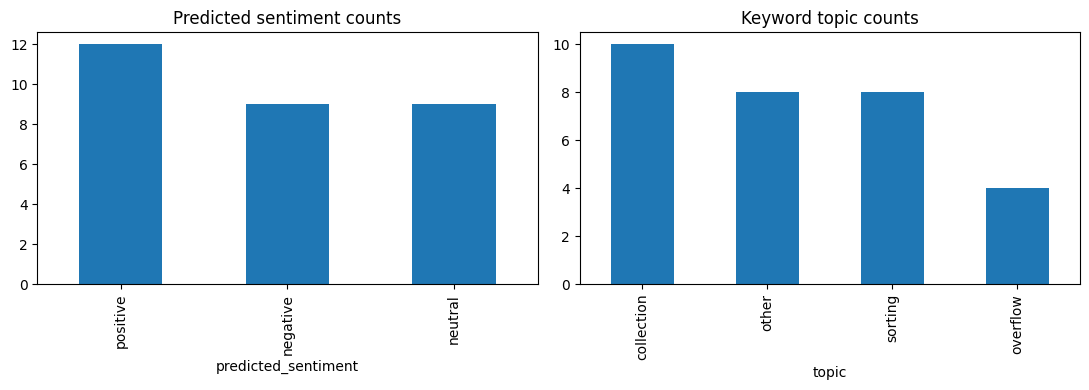

In [114]:
def detect_topic(text, rules):
    if pd.isna(text) or not str(text).strip():
        return "other", None
    lowered = str(text).lower()
    for topic, keywords in rules.items():
        for keyword in keywords:
            if keyword.lower() in lowered:
                return topic, keyword
    return "other", None

topic_results = feedback_results.copy()
topic_pairs = topic_results["text"].apply(lambda value: detect_topic(value, topic_keywords))
topic_results["topic"] = topic_pairs.apply(lambda item: item[0])
topic_results["matched_keyword"] = topic_pairs.apply(lambda item: item[1])

display(topic_results[["comment_id", "text", "topic", "matched_keyword"]])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
feedback_results["predicted_sentiment"].value_counts().plot(kind="bar", ax=axes[0], title="Predicted sentiment counts")
topic_results["topic"].value_counts().plot(kind="bar", ax=axes[1], title="Keyword topic counts")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "nlp_feedback_charts.png", dpi=160, bbox_inches="tight")
plt.show()

topic_results.to_csv(REPORTS_DIR / "feedback_analysis.csv", index=False)

## Cell 48 — Save NLP metadata and metrics

In [115]:
nlp_metrics = {
    "reference_rows": int(len(labelled_feedback)),
    "vader_accuracy": float(sentiment_accuracy),
    "vader_macro_f1": float(sentiment_macro_f1),
    "note": "VADER is lexicon-based, not trained on the supplied comments."
}
(REPORTS_DIR / "nlp_metrics.json").write_text(json.dumps(nlp_metrics, indent=2))
(MODELS_DIR / "topic_keywords.json").write_text(json.dumps(topic_keywords, indent=2))
print("Saved NLP metrics, topic rules and feedback analysis.")

Saved NLP metrics, topic rules and feedback analysis.


# Part E — Final model inventory and backup

## Cell 49 — Check all saved model artifacts

In [116]:

# Final Model Artifact Verification

expected_artifacts = [
    MODELS_DIR / "supervised.joblib",
    MODELS_DIR / "baseline.joblib",
    MODELS_DIR / "supervised_metadata.json",

    MODELS_DIR / "clusters.joblib",
    MODELS_DIR / "cluster_metadata.json",

    MODELS_DIR / "images.keras",
    MODELS_DIR / "image_metadata.json",

    MODELS_DIR / "topic_keywords.json",

    REPORTS_DIR / "supervised_metrics.json",
    REPORTS_DIR / "mobilenetv2_test_metrics.json",
    REPORTS_DIR / "kmeans_group_summary.csv"
]

print("=" * 60)
print("FINAL PROJECT ARTIFACT CHECK")
print("=" * 60)

for path in expected_artifacts:

    if path.exists():
        size = path.stat().st_size / (1024 * 1024)

        print(
            f"OK: {path.name} ({size:.2f} MB)"
        )

    else:
        print(f"MISSING: {path.name}")

missing = [
    path.name for path in expected_artifacts
    if not path.exists()
]

assert not missing, (
    "Missing artifacts: " + ", ".join(missing)
)

print("\nAll required artifacts are available.")


FINAL PROJECT ARTIFACT CHECK
OK: supervised.joblib (0.01 MB)
OK: baseline.joblib (0.00 MB)
OK: supervised_metadata.json (0.00 MB)
OK: clusters.joblib (0.00 MB)
OK: cluster_metadata.json (0.00 MB)
OK: images.keras (3.47 MB)
OK: image_metadata.json (0.00 MB)
OK: topic_keywords.json (0.00 MB)
OK: supervised_metrics.json (0.00 MB)
OK: mobilenetv2_test_metrics.json (0.00 MB)
OK: kmeans_group_summary.csv (0.00 MB)

All required artifacts are available.


## Cell 50 — Download the completed Project_03 folder as a ZIP

This creates a ZIP backup containing the Project_03 folder, saved models, reports, sample images, supplied small data files and source notices. The original full image arrays remain in the project folder; for the public GitHub app repository, follow the assignment's `.gitignore` guidance and do not upload `images.npz` or the original dataset ZIP.

In [117]:
import shutil
BACKUP_ZIP = shutil.make_archive(
    "/content/Project_03_trained_backup",
    "zip",
    root_dir=PROJECT_DIR.parent,
    base_dir=PROJECT_DIR.name
)
print("Backup created:", BACKUP_ZIP)
files.download(BACKUP_ZIP)

Backup created: /content/Project_03_trained_backup.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [118]:

import os
import zipfile

backup_path = "/content/Project_03_trained_backup.zip"

print("Backup size:",
      round(os.path.getsize(backup_path) / (1024 * 1024), 2),
      "MB")

with zipfile.ZipFile(backup_path, "r") as z:
    print("\nBackup contents:")
    for name in z.namelist()[:50]:
        print(name)

    print("\nTotal files:", len(z.namelist()))


Backup size: 25.66 MB

Backup contents:
Project_03/
Project_03/data/
Project_03/models/
Project_03/nltk_data/
Project_03/reports/
Project_03/sample_images/
Project_03/source_notices/
Project_03/README.md
Project_03/Start_Here_Colab.ipynb
Project_03/data/example_inputs.csv
Project_03/data/feedback.csv
Project_03/data/images.npz
Project_03/data/image_manifest.csv
Project_03/data/main.csv
Project_03/data/meta.json
Project_03/data/prompt_test_cases.json
Project_03/data/topic_keywords.json
Project_03/nltk_data/sentiment/
Project_03/nltk_data/sentiment/vader_lexicon/
Project_03/nltk_data/sentiment/vader_lexicon.zip
Project_03/nltk_data/sentiment/vader_lexicon/vader_lexicon.txt
Project_03/sample_images/0_paper.png
Project_03/sample_images/1_plastic.png
Project_03/sample_images/2_metal.png
Project_03/source_notices/ATTRIBUTION.txt
Project_03/source_notices/nltk_LICENSE.txt
Project_03/source_notices/trashnet_LICENSE.txt
Project_03/models/supervised.joblib
Project_03/models/baseline.joblib
Proje

# Expected outputs and how to judge the results

- `supervised.joblib`: saved Decision Tree pipeline.
- `baseline.joblib`: saved DummyClassifier baseline.
- `clusters.joblib`: saved StandardScaler + KMeans pipeline.
- `images.keras`: saved CNN classifier.
- JSON metadata files: feature names, class order, descriptions and preprocessing information.
- `reports/`: EDA charts, validation/test metrics, confusion matrices, CNN learning curves, NLP outputs and test errors.

### Do not chase an arbitrary accuracy number
The dataset is a small generated classroom dataset. The comments are only 30 authored English examples and the image set is limited to three classes. A high score on these examples does not mean the system can identify every real-world waste item. Report the actual test metrics and explain errors honestly.

### Keep these limitations in the final report
- The tabular rows are generated teaching scenarios, not real sensor records.
- The CNN recognises only a single visible object among paper, plastic and metal; it is not a mixed-waste detector or unknown-material detector.
- VADER is an English lexicon-based sentiment method; it can struggle with sarcasm, negation and mixed opinions.
- The KMeans groups describe similarity; they are not collection priority labels.
- The ultrasonic IoT sensor extension is separate from this required training notebook and will be developed after the assignment models and manual Streamlit app are working.